# Setting up the environment
## Importing dependancies

In [117]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import os

## Setup

In [118]:
sns.set_theme(
    style="whitegrid",
    palette="deep",
    context="notebook"
)

plt.rcParams["figure.dpi"] = 100

dataPath='../data/raw/telco.csv'
figuresPath='../reports/figures/'
os.makedirs(figuresPath, exist_ok=True)

def saveFigure(name):
    '''save the current figure to the figures directory'''
    plt.savefig(os.path.join(figuresPath, name), bbox_inches='tight', dpi=300)

In [119]:
df= pd.read_csv(dataPath)
df.head()


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


# Dataset overview

In [120]:
print(f'The shape of the dataset is {df.shape[0]} rows and {df.shape[1]} columns')



The shape of the dataset is 7043 rows and 21 columns


In [121]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [122]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [123]:
df.isna().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [124]:
df.duplicated().sum()

np.int64(0)

In [125]:
df.customerID.is_unique

True

In [126]:
df.nunique()

customerID          7043
gender                 2
SeniorCitizen          2
Partner                2
Dependents             2
tenure                73
PhoneService           2
MultipleLines          3
InternetService        3
OnlineSecurity         3
OnlineBackup           3
DeviceProtection       3
TechSupport            3
StreamingTV            3
StreamingMovies        3
Contract               3
PaperlessBilling       2
PaymentMethod          4
MonthlyCharges      1585
TotalCharges        6531
Churn                  2
dtype: int64

**Observations**
- 7,043 rows and 21 columns, with no duplicate rows and a unique `customerID` (an identifier with no predictive value, to be dropped in preprocessing).
- `isna()` reports no missing values, **but** `TotalCharges` is stored as text rather than a number, which usually means hidden blanks (investigated next).
- Only `tenure`, `MonthlyCharges` and `TotalCharges` are continuous. Every other feature is categorical (including `SeniorCitizen`, which is stored as 0/1).

# The datatypes


In [127]:
df.dtypes

customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges            str
Churn                   str
dtype: object

## Changing the type of `TotalCharges`

In [128]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors='coerce')

In [129]:
print(df["TotalCharges"].isna().sum())

11


In [130]:
df[df["TotalCharges"].isna()]

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,NaN,No
753,3115-CZMZD,Male,0,No,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,NaN,No
936,5709-LVOEQ,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,...,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,NaN,No
1082,4367-NUYAO,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,NaN,No
1340,1371-DWPAZ,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,NaN,No
3331,7644-OMVMY,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,NaN,No
3826,3213-VVOLG,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,NaN,No
4380,2520-SGTTA,Female,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,NaN,No
5218,2923-ARZLG,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,NaN,No
6670,4075-WKNIU,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,...,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,NaN,No


**Observations**
- 11 customers have a blank `TotalCharges`, and **all of them have `tenure = 0`**. They are brand-new customers who have not yet been billed, so the blank is structurally meaningful rather than a data-entry error. None of them churned.
- **Decision for preprocessing (not applied here):** set `TotalCharges` to 0 for these rows (they genuinely have been charged nothing) or drop them (11 rows is 0.16% of the data). Either option is defensible and the choice will be justified in the report.

# Checking the target variable

In [131]:
df["Churn_num"] = (df["Churn"] == "Yes").astype(int)


In [132]:
churn_count=df['Churn'].value_counts()
print(churn_count)

Churn
No     5174
Yes    1869
Name: count, dtype: int64


In [133]:
percent = df["Churn"].value_counts(normalize=True).mul(100).round(2)
print(pd.DataFrame({"count": churn_count, "percent": percent}))

       count  percent
Churn                
No      5174    73.46
Yes     1869    26.54


C:\Users\LOQ\AppData\Local\Temp\ipykernel_760\3356745186.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x="Churn", order=["No", "Yes"], ax=ax,palette=["#2176ff", "#ff2b2b"])


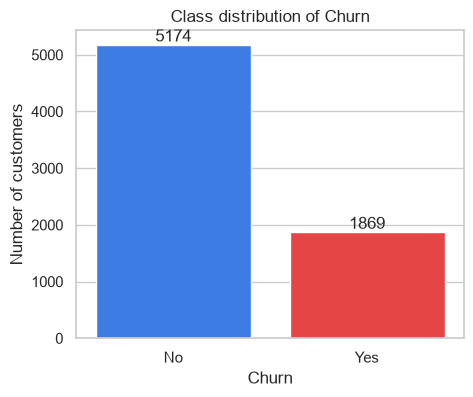

In [134]:
fig, ax = plt.subplots(figsize=(5, 4))
sns.countplot(data=df, x="Churn", order=["No", "Yes"], ax=ax,palette=["#2176ff", "#ff2b2b"])
for p in ax.patches:
    ax.annotate(f"{int(p.get_height())}", (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom")
ax.set_title("Class distribution of Churn")
ax.set_xlabel("Churn")
ax.set_ylabel("Number of customers")
saveFigure("01_churn_distribution")
plt.show()

**Observations**
- 5,174 customers stayed (73.5%) and 1,869 churned (26.5%): a moderate **class imbalance**.
- **Implication:** a model that always predicts "No" would score about 73.5% accuracy while catching no churners, so accuracy alone is misleading. Evaluation must also use precision, recall, F1 and ROC-AUC, and the train/test split should be **stratified** on `Churn`.

# Univariate analysis

## Numeric features

In [135]:
numeric_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']

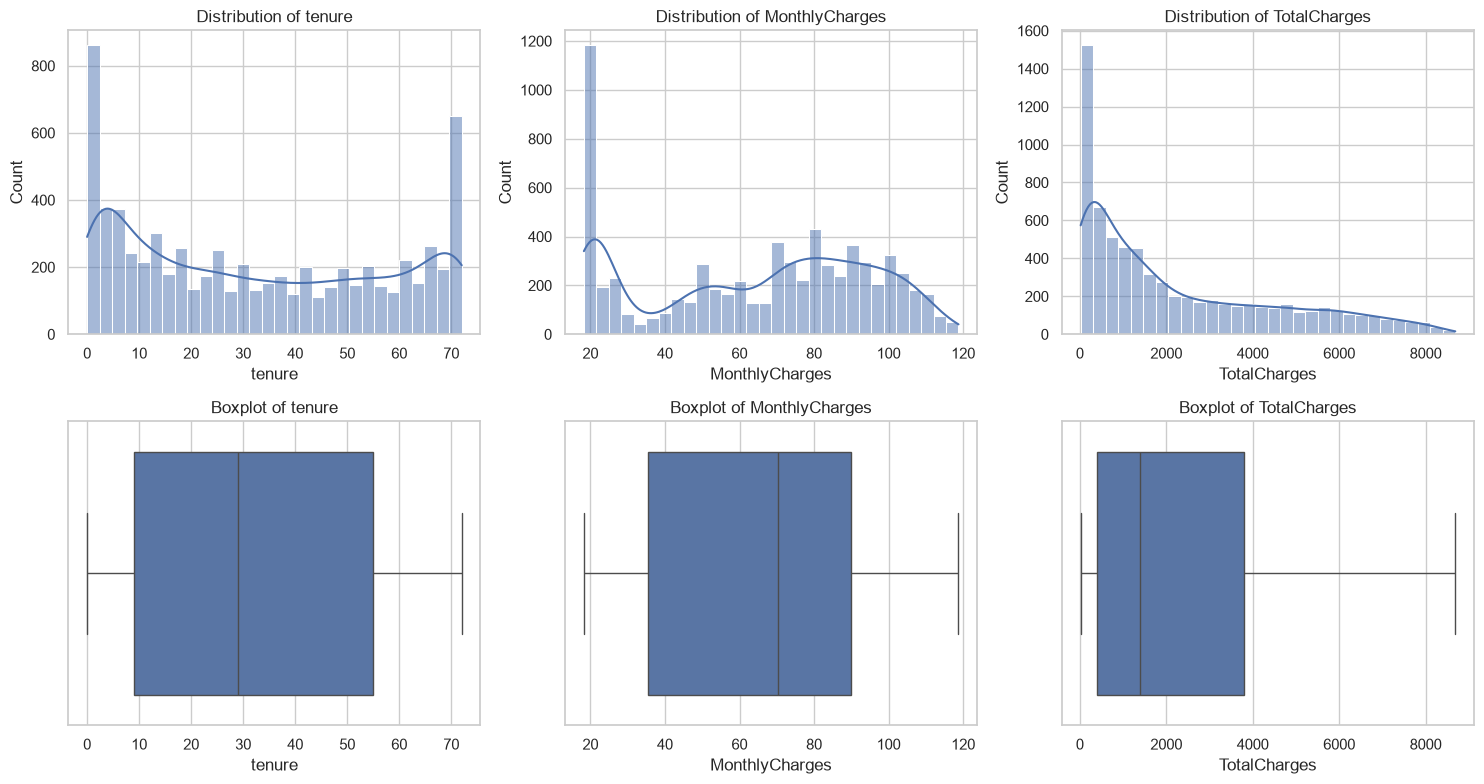

In [136]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for i, col in enumerate(numeric_cols):
    sns.histplot(df[col], kde=True, bins=30, ax=axes[0, i])
    axes[0, i].set_title(f"Distribution of {col}")
    sns.boxplot(x=df[col], ax=axes[1, i])
    axes[1, i].set_title(f"Boxplot of {col}")
plt.tight_layout()
saveFigure("02_numeric_univariate")
plt.show()

In [137]:
summary = pd.DataFrame({
    "skew": df[numeric_cols].skew(),
    "outliers_IQR": [
        ((df[c] < df[c].quantile(0.25) - 1.5 * (df[c].quantile(0.75) - df[c].quantile(0.25))) |
         (df[c] > df[c].quantile(0.75) + 1.5 * (df[c].quantile(0.75) - df[c].quantile(0.25)))).sum()
        for c in numeric_cols
    ],
})
summary

,skew,outliers_IQR
tenure,0.239540,0
MonthlyCharges,-0.220524,0
TotalCharges,0.961642,0


**Observations**
- `tenure` is **bimodal**: many customers are very new (0-5 months) and many have stayed the full 72 months.
- `MonthlyCharges` has a large cluster around \$20 (customers with phone service only) and a broad spread above \$60.
- `TotalCharges` is **right-skewed** because it accumulates with tenure.
- The boxplots show no problematic outliers, so no rows need to be removed for outliers.
- **Implication:** none of the three is normally distributed, and their scales are very different (0-72 vs 18-119 vs 0-8,700). **Scaling is essential for KNN and Logistic Regression**, while Random Forest would be unaffected.

## Categorical features

In [138]:
cat_cols = [
    'gender',
    'SeniorCitizen',
    'Partner',
    'Dependents',
    'PhoneService',
    'MultipleLines',
    'InternetService',
    'OnlineSecurity',
    'OnlineBackup',
    'DeviceProtection',
    'TechSupport',
    'StreamingTV',
    'StreamingMovies',
    'Contract',
    'PaperlessBilling',
    'PaymentMethod'
]

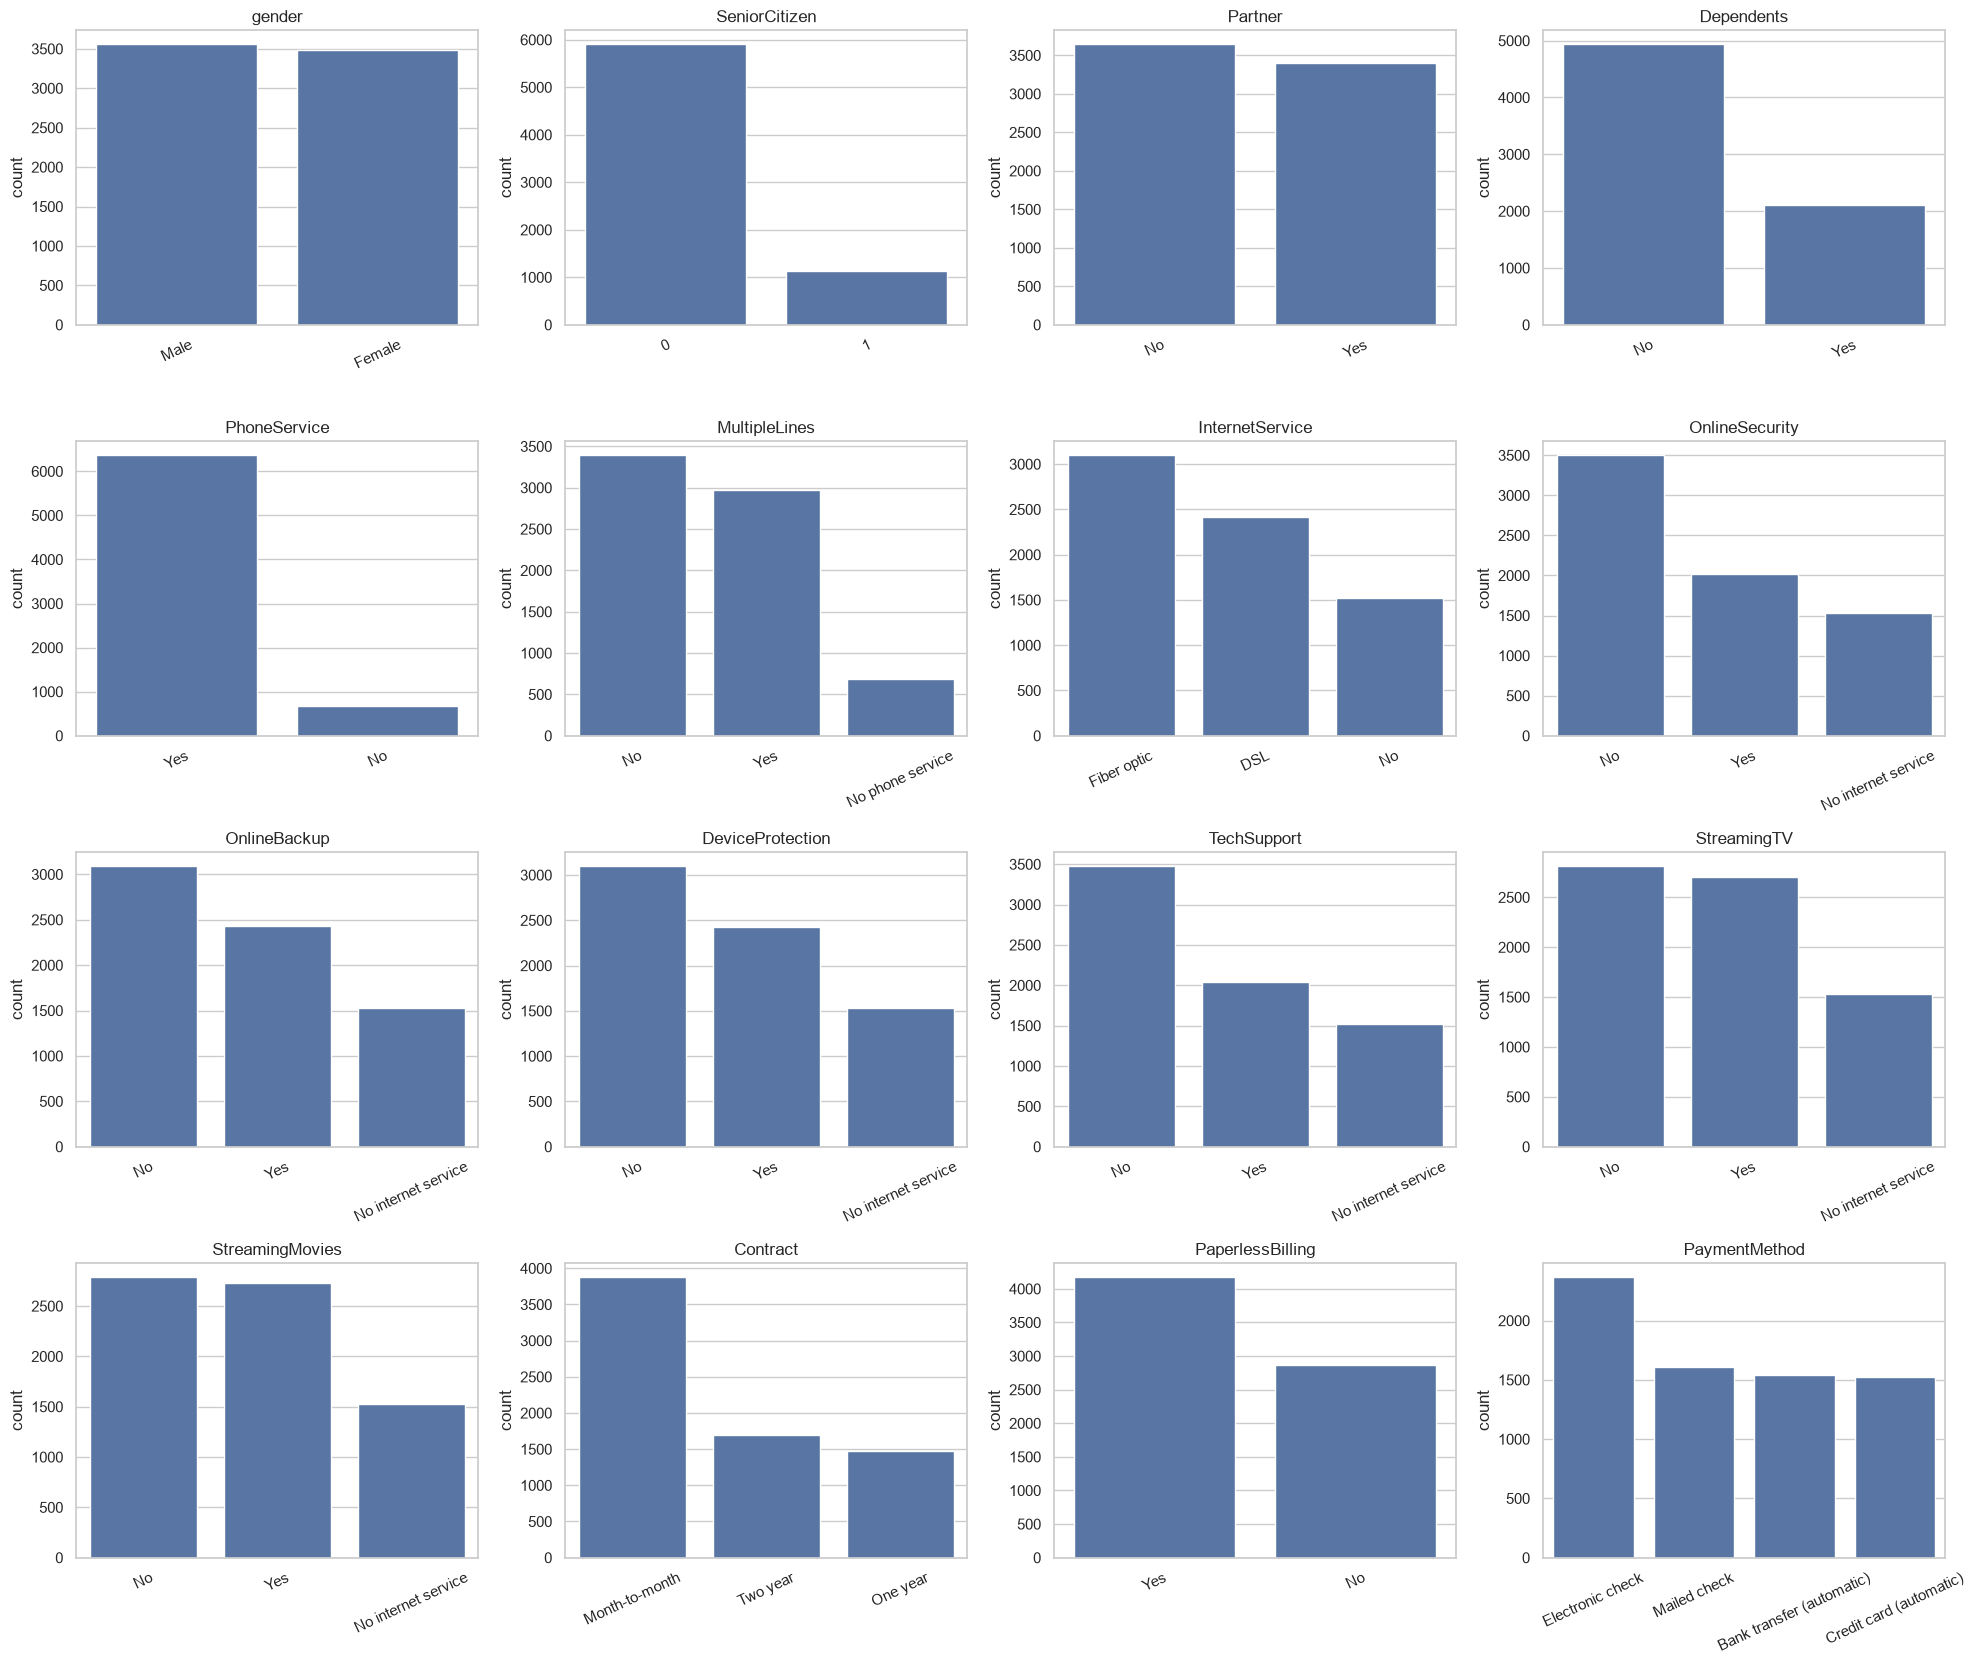

In [139]:
n_cols = 4
n_rows = int(np.ceil(len(cat_cols) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, 4.2 * n_rows))
axes = axes.flatten()
for ax, col in zip(axes, cat_cols):
    order = df[col].value_counts().index
    sns.countplot(data=df, x=col, order=order, ax=ax)
    ax.set_title(col)
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=25)
for ax in axes[len(cat_cols):]:
    ax.set_visible(False)
plt.tight_layout()
saveFigure("03_categorical_univariate")
plt.show()

In [140]:
for col in cat_cols:
    print(f"\n{col}")
    print(df[col].value_counts(normalize=True).round(3) * 100)


gender
gender
Male      50.5
Female    49.5
Name: proportion, dtype: float64

SeniorCitizen
SeniorCitizen
0    83.8
1    16.2
Name: proportion, dtype: float64

Partner
Partner
No     51.7
Yes    48.3
Name: proportion, dtype: float64

Dependents
Dependents
No     70.0
Yes    30.0
Name: proportion, dtype: float64

PhoneService
PhoneService
Yes    90.3
No      9.7
Name: proportion, dtype: float64

MultipleLines
MultipleLines
No                  48.1
Yes                 42.2
No phone service     9.7
Name: proportion, dtype: float64

InternetService
InternetService
Fiber optic    44.0
DSL            34.4
No             21.7
Name: proportion, dtype: float64

OnlineSecurity
OnlineSecurity
No                     49.7
Yes                    28.7
No internet service    21.7
Name: proportion, dtype: float64

OnlineBackup
OnlineBackup
No                     43.8
Yes                    34.5
No internet service    21.7
Name: proportion, dtype: float64

DeviceProtection
DeviceProtection
No          

**Observations**
- `gender` is almost perfectly balanced; `SeniorCitizen` is a minority (about 16%); `PhoneService` is overwhelmingly "Yes".
- `Contract` is dominated by month-to-month customers, and `InternetService` is mostly Fiber optic or DSL.
- Several columns carry a third level "No internet service" (or "No phone service"), which duplicates information already held in `InternetService` / `PhoneService` (see Section 7).

# Bivariate analysis against churn
## Categorical features vs churn rate

In [141]:
overall_rate = df["Churn_num"].mean() * 100
overall_rate

np.float64(26.536987079369588)

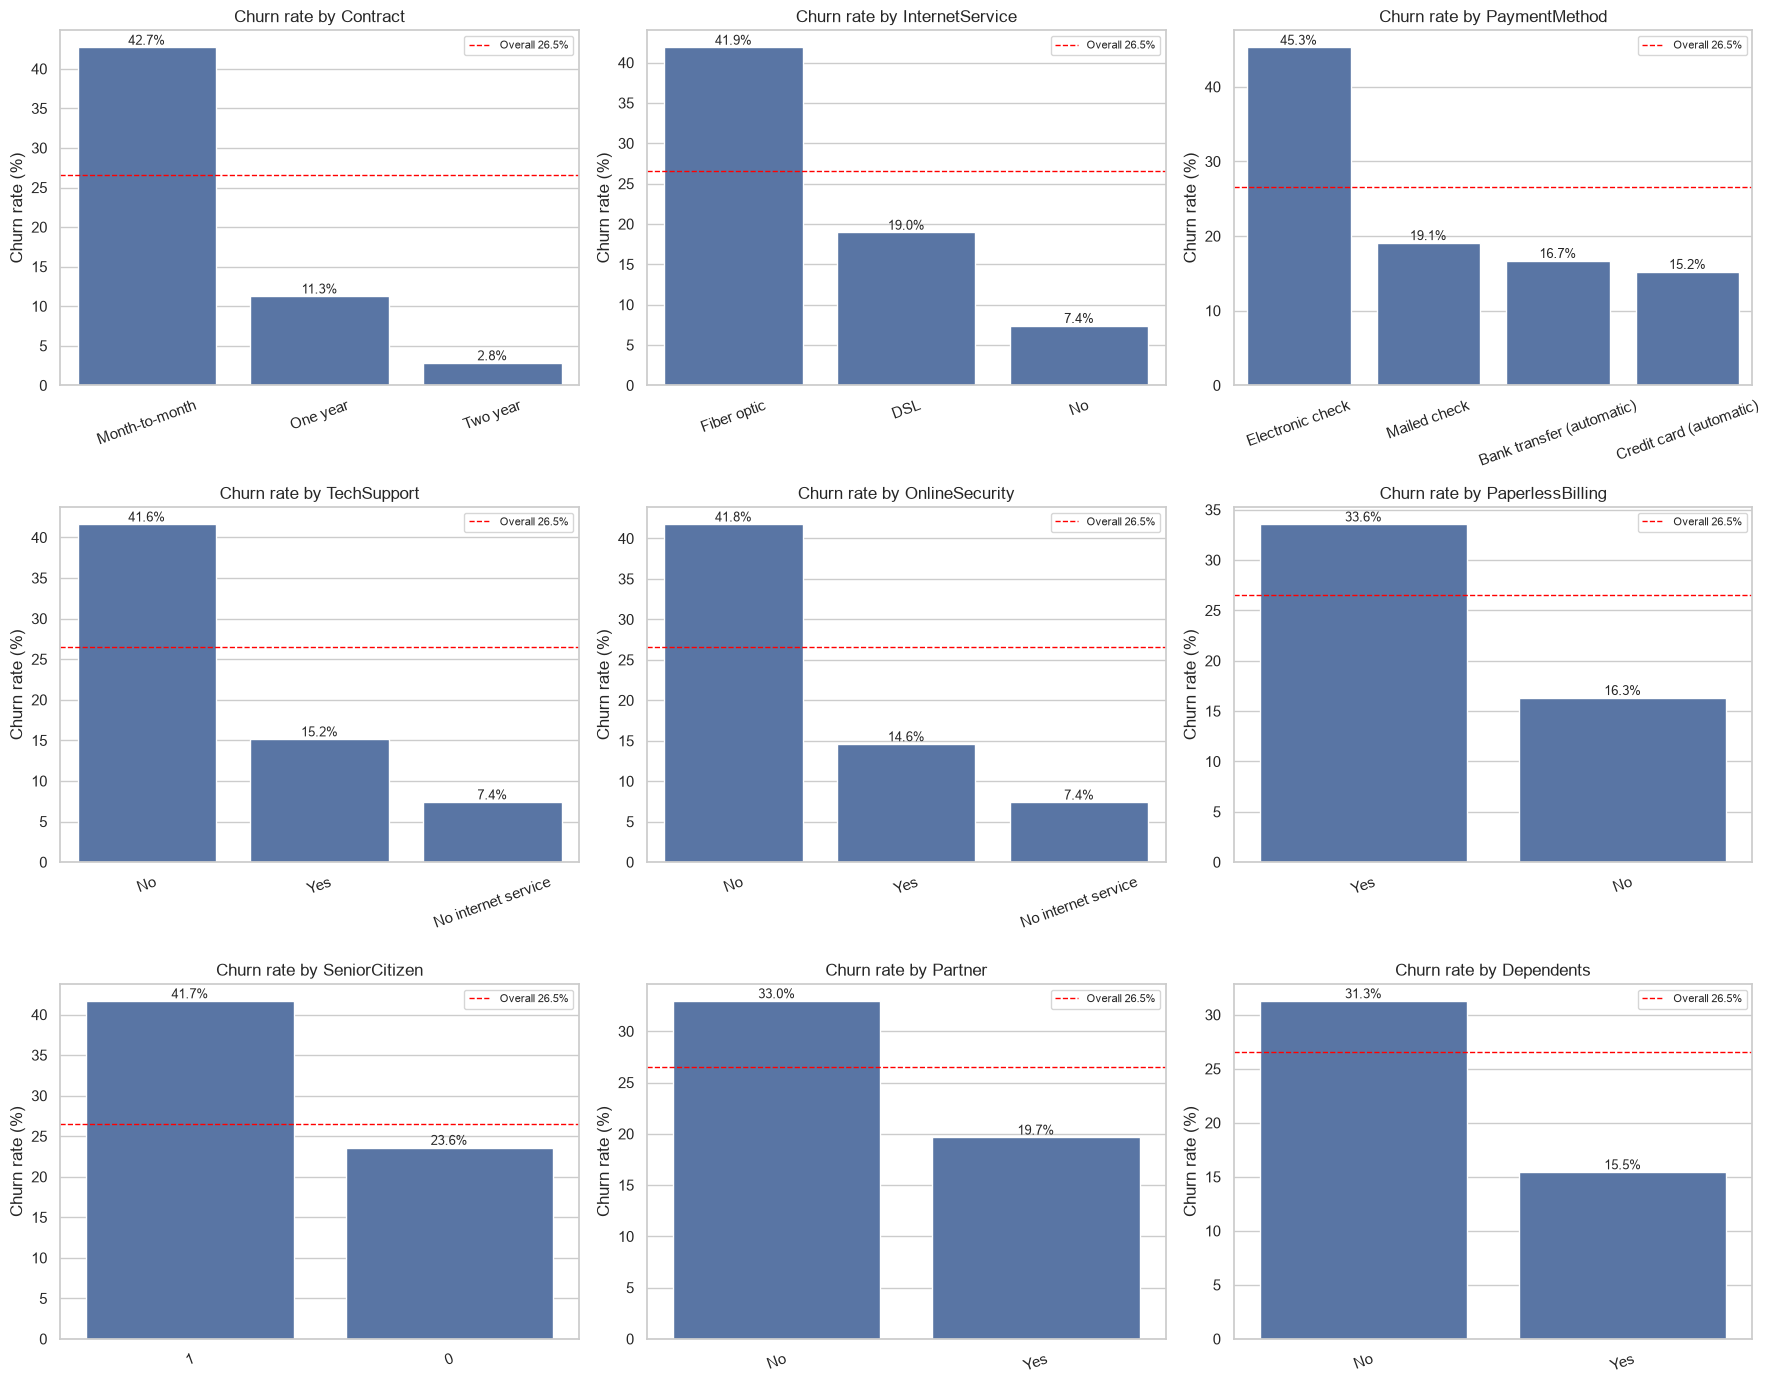

In [142]:
def churn_rate_plot(col, ax):
    rate = df.groupby(col)["Churn_num"].mean().mul(100).sort_values(ascending=False)
    sns.barplot(x=rate.index.astype(str), y=rate.values, ax=ax)
    ax.axhline(overall_rate, color="red", linestyle="--", linewidth=1, label=f"Overall {overall_rate:.1f}%")
    for p in ax.patches:
        ax.annotate(f"{p.get_height():.1f}%", (p.get_x() + p.get_width() / 2, p.get_height()),
                    ha="center", va="bottom", fontsize=9)
    ax.set_title(f"Churn rate by {col}")
    ax.set_xlabel("")
    ax.set_ylabel("Churn rate (%)")
    ax.tick_params(axis="x", rotation=20)
    ax.legend(loc="upper right", fontsize=8)

key_cols = ["Contract", "InternetService", "PaymentMethod", "TechSupport",
            "OnlineSecurity", "PaperlessBilling", "SeniorCitizen", "Partner", "Dependents"]

fig, axes = plt.subplots(3, 3, figsize=(18, 14))
for ax, col in zip(axes.flatten(), key_cols):
    churn_rate_plot(col, ax)
plt.tight_layout()
saveFigure("04_churn_rate_key_categoricals")
plt.show()

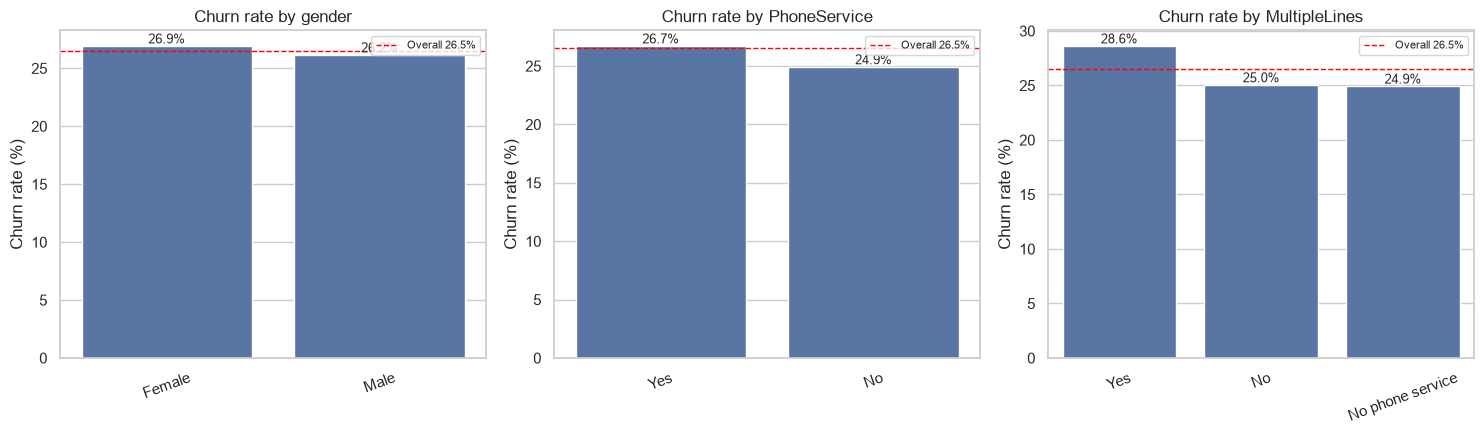

In [143]:
low_cols = ["gender", "PhoneService", "MultipleLines"]
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, col in zip(axes, low_cols):
    churn_rate_plot(col, ax)
plt.tight_layout()
saveFigure("05_churn_rate_weak_categoricals")
plt.show()

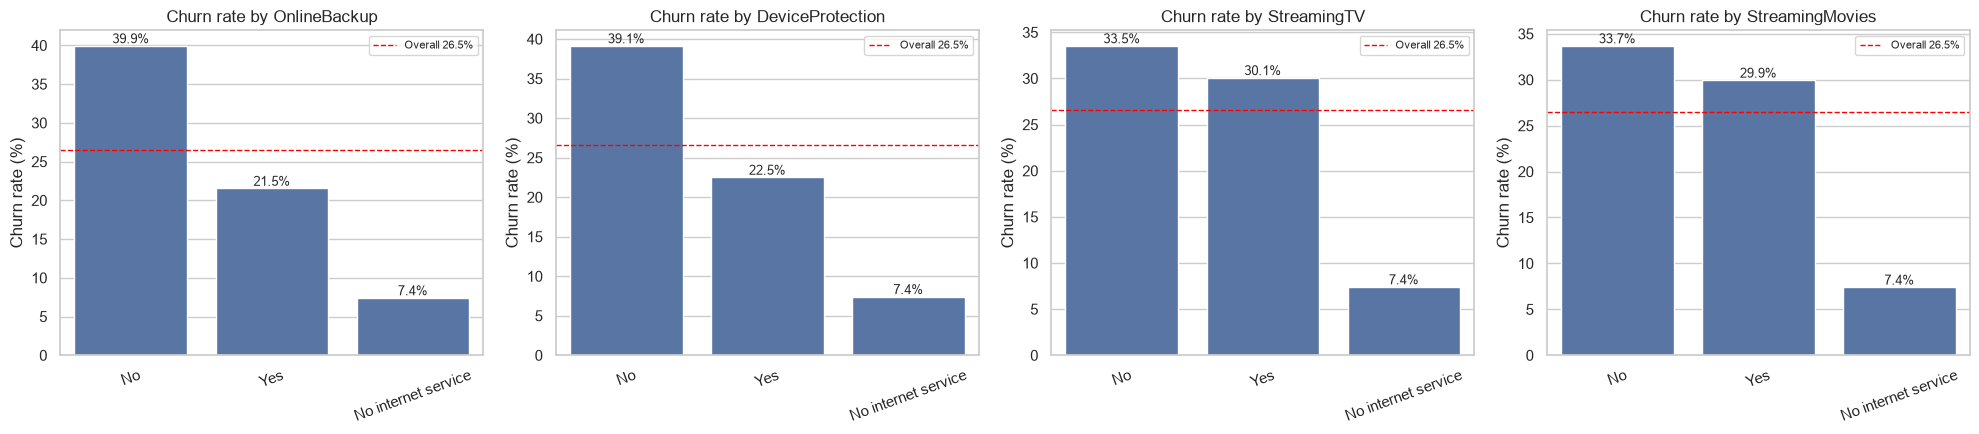

In [144]:
rest = ["OnlineBackup", "DeviceProtection", "StreamingTV", "StreamingMovies"]
fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
for ax, col in zip(axes, rest):
    churn_rate_plot(col, ax)
plt.tight_layout()
saveFigure("06_churn_rate_other_services")
plt.show()

**Observations**
- **`Contract` is the strongest driver:** month-to-month 42.7%, one-year 11.3%, two-year 2.8%.
- **`InternetService`:** Fiber optic customers churn at 41.9% versus 19.0% for DSL and 7.4% for no internet.
- **`PaymentMethod`:** electronic check is far higher (45.3%) than the other three methods (15-19%).
- **Support/security add-ons protect against churn:** customers without `TechSupport` (41.6%) or `OnlineSecurity` (41.8%) churn about 2.7x more than those with them (15.2% and 14.6%).
- **Demographics:** senior citizens churn at 41.7% (vs 23.6%); customers with a partner (19.7% vs 33.0%) or dependents (15.5% vs 31.3%) churn less. `PaperlessBilling` customers churn at 33.6% vs 16.3%.
- **`gender` (26.9% vs 26.2%) and `PhoneService` (26.7% vs 24.9%) have almost no relationship with churn**, so they are weak predictors. `gender` is also a protected attribute (relevant for the AI ethics task).`

## Numeric features vs churn

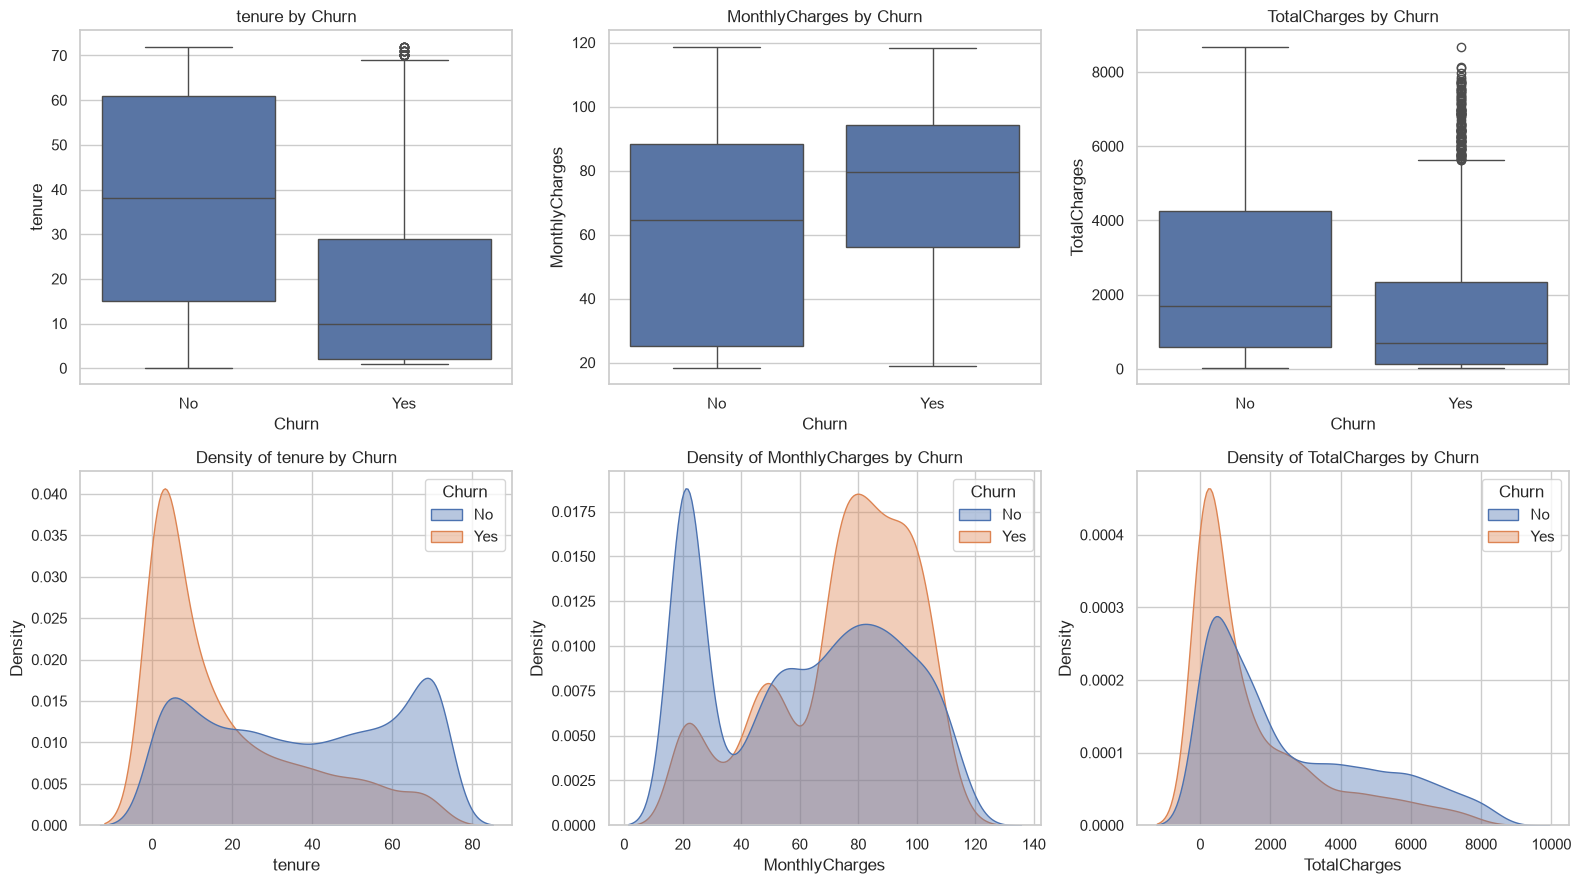

In [145]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for i, col in enumerate(numeric_cols):
    sns.boxplot(data=df, x="Churn", y=col, order=["No", "Yes"], ax=axes[0, i])
    axes[0, i].set_title(f"{col} by Churn")
    sns.kdeplot(data=df, x=col, hue="Churn", common_norm=False, fill=True, alpha=0.4, ax=axes[1, i])
    axes[1, i].set_title(f"Density of {col} by Churn")
plt.tight_layout()
saveFigure("07_numeric_vs_churn")
plt.show()

In [146]:
df.groupby("Churn")[numeric_cols].median().round(2)

,tenure,MonthlyCharges,TotalCharges
Churn,,,
No,38.0,64.43,1683.60
Yes,10.0,79.65,703.55


**Observations**
- **Churners are newer customers:** median tenure is 10 months for churners vs 38 months for those who stayed.
- **Churners pay more per month:** median `MonthlyCharges` is about \$79.65 vs \$64.43.
- Median `TotalCharges` is much lower for churners (about \$704 vs \$1,684), but this is largely a side effect of their short tenure rather than an independent signal.

## Churn rate by tenure band

In [147]:
bins = [-1, 12, 24, 48, 72]
labels = ["0-12", "13-24", "25-48", "49-72"]
df["tenure_band"] = pd.cut(df["tenure"], bins=bins, labels=labels)

In [148]:
band_rate = df.groupby("tenure_band", observed=True)["Churn_num"].mean().mul(100)
band_rate

tenure_band
0-12     47.438243
13-24    28.710938
25-48    20.388959
49-72     9.513176
Name: Churn_num, dtype: float64

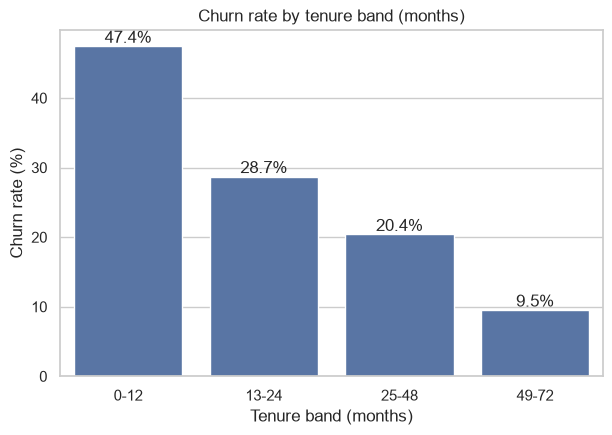

In [149]:
fig, ax = plt.subplots(figsize=(7, 4.5))
sns.barplot(x=band_rate.index.astype(str), y=band_rate.values, ax=ax)
for p in ax.patches:
    ax.annotate(f"{p.get_height():.1f}%", (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom")
ax.set_title("Churn rate by tenure band (months)")
ax.set_xlabel("Tenure band (months)")
ax.set_ylabel("Churn rate (%)")
saveFigure("08_churn_by_tenure_band")
plt.show()

**Observations**
- Churn falls steadily with tenure: 47.4% in the first year, 28.7% in year two, 20.4% in years three to four, and 9.5% beyond four years.
- **Implication:** the first 12 months are the critical retention window.

## Combined effect: contract type and tenure

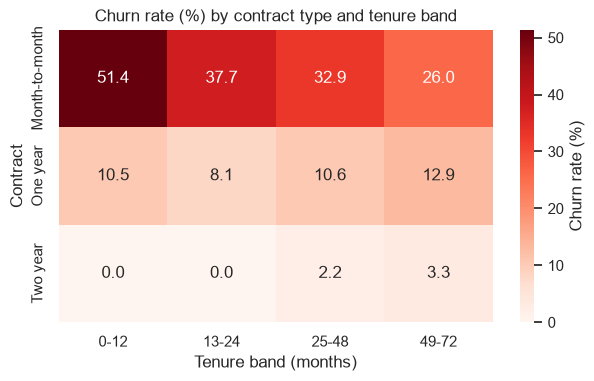

In [150]:
pivot = (df.pivot_table(index="Contract", columns="tenure_band", values="Churn_num",
                        aggfunc="mean", observed=True) * 100).round(1)

fig, ax = plt.subplots(figsize=(7, 3.8))
sns.heatmap(pivot, annot=True, fmt=".1f", cmap="Reds", cbar_kws={"label": "Churn rate (%)"}, ax=ax)
ax.set_title("Churn rate (%) by contract type and tenure band")
ax.set_xlabel("Tenure band (months)")
saveFigure("09_contract_tenure_heatmap")
plt.show()

**Observation:** the two effects compound. New month-to-month customers are the highest-risk group, while long-tenure customers on one- or two-year contracts almost never churn.

# Correlation and redundancy
## Numeric correlation

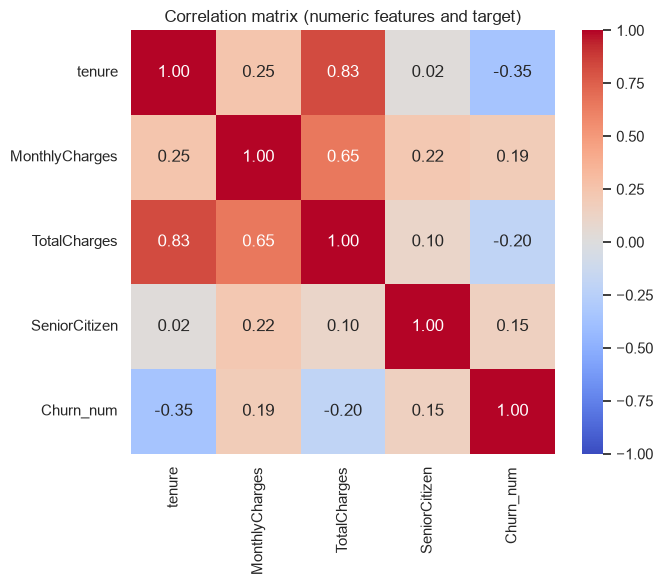

In [151]:
corr_cols = ["tenure", "MonthlyCharges", "TotalCharges", "SeniorCitizen", "Churn_num"]
corr = df[corr_cols].corr()

fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True, ax=ax)
ax.set_title("Correlation matrix (numeric features and target)")
saveFigure("10_correlation_heatmap")
plt.show()

In [152]:
expected_total = df["tenure"] * df["MonthlyCharges"]
print("Correlation(TotalCharges, tenure * MonthlyCharges):",
      round(df["TotalCharges"].corr(expected_total), 4))

Correlation(TotalCharges, tenure * MonthlyCharges): 0.9996


**Observations**
- `tenure` has the strongest (negative) correlation with churn (-0.35), followed by `TotalCharges` (-0.20) and `MonthlyCharges` (+0.19).
- `TotalCharges` is highly correlated with `tenure` (0.83) and with `MonthlyCharges` (0.65), and it is almost exactly `tenure x MonthlyCharges` (r = 0.9996). It is therefore **largely redundant**.
- **Implication:** this multicollinearity can destabilise Logistic Regression coefficients and distort KNN distances. Preprocessing should consider dropping `TotalCharges` or testing the models with and without it.

## Redundant categorical levels

In [153]:
dependent_cols = ["OnlineSecurity", "OnlineBackup", "DeviceProtection",
                  "TechSupport", "StreamingTV", "StreamingMovies"]

# 'No internet service' should appear exactly as often as InternetService == 'No'
print("InternetService == 'No':", (df["InternetService"] == "No").sum())
for c in dependent_cols:
    print(f"{c:18s} 'No internet service':", (df[c] == "No internet service").sum())

print("\nPhoneService == 'No':", (df["PhoneService"] == "No").sum())
print("MultipleLines 'No phone service':", (df["MultipleLines"] == "No phone service").sum())

InternetService == 'No': 1526
OnlineSecurity     'No internet service': 1526
OnlineBackup       'No internet service': 1526
DeviceProtection   'No internet service': 1526
TechSupport        'No internet service': 1526
StreamingTV        'No internet service': 1526
StreamingMovies    'No internet service': 1526

PhoneService == 'No': 682
MultipleLines 'No phone service': 682


**Observations**
- The "No internet service" level appears in exactly the same 1,526 rows in all six internet-dependent columns, matching `InternetService == "No"`. "No phone service" in `MultipleLines` likewise matches `PhoneService == "No"` (682 rows).
- **Implication:** these levels carry no new information. In preprocessing they can be merged into "No" (leaving clean Yes/No features), because the internet/phone status is already captured by `InternetService` and `PhoneService`.

# Summary of insights and preprocessing decisions

### Key findings

| # | Finding | Evidence |
|---|---------|----------|
| 1 | Moderate class imbalance | 26.5% churn vs 73.5% retained |
| 2 | Contract type is the strongest driver | Churn 42.7% (month-to-month) vs 11.3% (1-year) vs 2.8% (2-year) |
| 3 | Early tenure is the highest risk period | 47.4% churn in months 0-12 falling to 9.5% beyond 48 months |
| 4 | Fiber optic customers churn far more | 41.9% vs 19.0% (DSL) |
| 5 | Electronic check users churn most | 45.3% vs 15-19% for other methods |
| 6 | Tech support and online security reduce churn | about 15% with vs about 42% without |
| 7 | Senior citizens, single customers and those without dependents churn more | 41.7% / 33.0% / 31.3% |
| 8 | Higher monthly bills are associated with churn | Median \$79.65 (churn) vs \$64.43 (retained) |
| 9 | `gender` and `PhoneService` are weak predictors | Churn rates differ by under 2 percentage points |
| 10 | `TotalCharges` is largely redundant | r = 0.83 with `tenure`; r = 0.9996 with `tenure x MonthlyCharges` |

### Data quality issues to beb resolve in preprocessing
1. **`TotalCharges`** is stored as text with 11 blank values (all `tenure = 0`): convert to numeric and will impute to 0 .
2. **`customerID`** is an identifier: will drop it.
3. **"No internet service" / "No phone service"** levels are redundant: will merge those into "No".
4. **Encoding:** binary Yes/No columns to 0/1, multi-level nominal columns (`Contract`, `InternetService`, `PaymentMethod`) to one-hot.
5. **Scaling:** `tenure`, `MonthlyCharges` (and `TotalCharges` if kept) must be standardised for KNN and Logistic Regression.
6. **Imbalance:** use a stratified split and evaluate with precision, recall, F1 and ROC-AUC (consider class weights or resampling).
7. **Multicollinearity:** test the models with and without `TotalCharges`.

### Ethical flags
- `gender` and `SeniorCitizen` are protected or sensitive attributes. `gender` shows no relationship with churn, and `SeniorCitizen` shows a strong one. Both need careful fairness analysis before deployment.